In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2021/2021-04-20/netflix_titles.csv"
df = pd.read_csv(url)

print(f"Dataset successfully loaded: {df.shape[0]} Rows, {df.shape[1]} Columns\n")
print("--- First 5 Records ---")
display(df.head())

Dataset successfully loaded: 7787 Rows, 12 Columns

--- First 5 Records ---


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",2020,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,7:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",2016,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",2011,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",2009,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",2008,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [2]:

df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce')
df['year_added'] = df['date_added'].dt.year
df['primary_country'] = df['country'].dropna().apply(lambda x: x.split(',')[0].strip())

df['rating'] = df['rating'].fillna('Unknown')

print("--- Preprocessed Attributes Summary ---")
print(f"Total Unique Titles       : {df['title'].nunique()}")
print(f"Content Types             : {df['type'].value_counts().to_dict()}")
print(f"Earliest Year Content Added: {int(df['year_added'].min())} | Latest: {int(df['year_added'].max())}")
print("\n✓ Data successfully prepared for publication-grade plotting!")

--- Preprocessed Attributes Summary ---
Total Unique Titles       : 7787
Content Types             : {'Movie': 5377, 'TV Show': 2410}
Earliest Year Content Added: 2008 | Latest: 2021

✓ Data successfully prepared for publication-grade plotting!


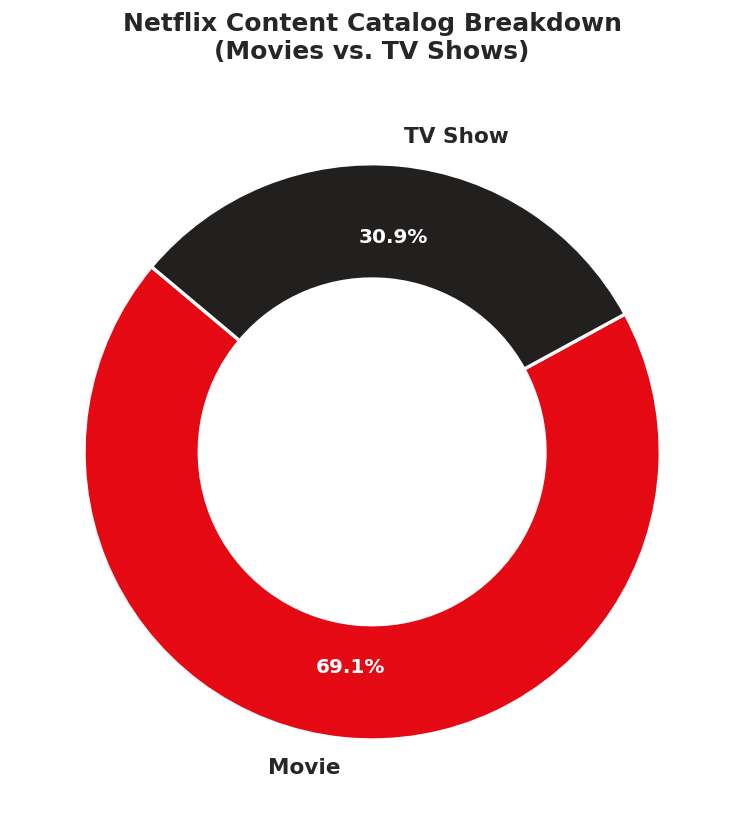

Total Movies   : 5,377 (69.1%)
Total TV Shows : 2,410 (30.9%)


In [3]:

type_counts = df['type'].value_counts()
colors = ['#E50914', '#221F1F']
plt.figure(figsize=(7, 7))

wedges, texts, autotexts = plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))

for text in texts:
    text.set_fontsize(13)
    text.set_fontweight('bold')
for autotext in autotexts:
    autotext.set_fontsize(12)
    autotext.set_color('white')
    autotext.set_fontweight('bold')

plt.title('Netflix Content Catalog Breakdown\n(Movies vs. TV Shows)', fontsize=15, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

print(f"Total Movies   : {type_counts.get('Movie', 0):,} ({type_counts.get('Movie', 0)/len(df)*100:.1f}%)")
print(f"Total TV Shows : {type_counts.get('TV Show', 0):,} ({type_counts.get('TV Show', 0)/len(df)*100:.1f}%)")

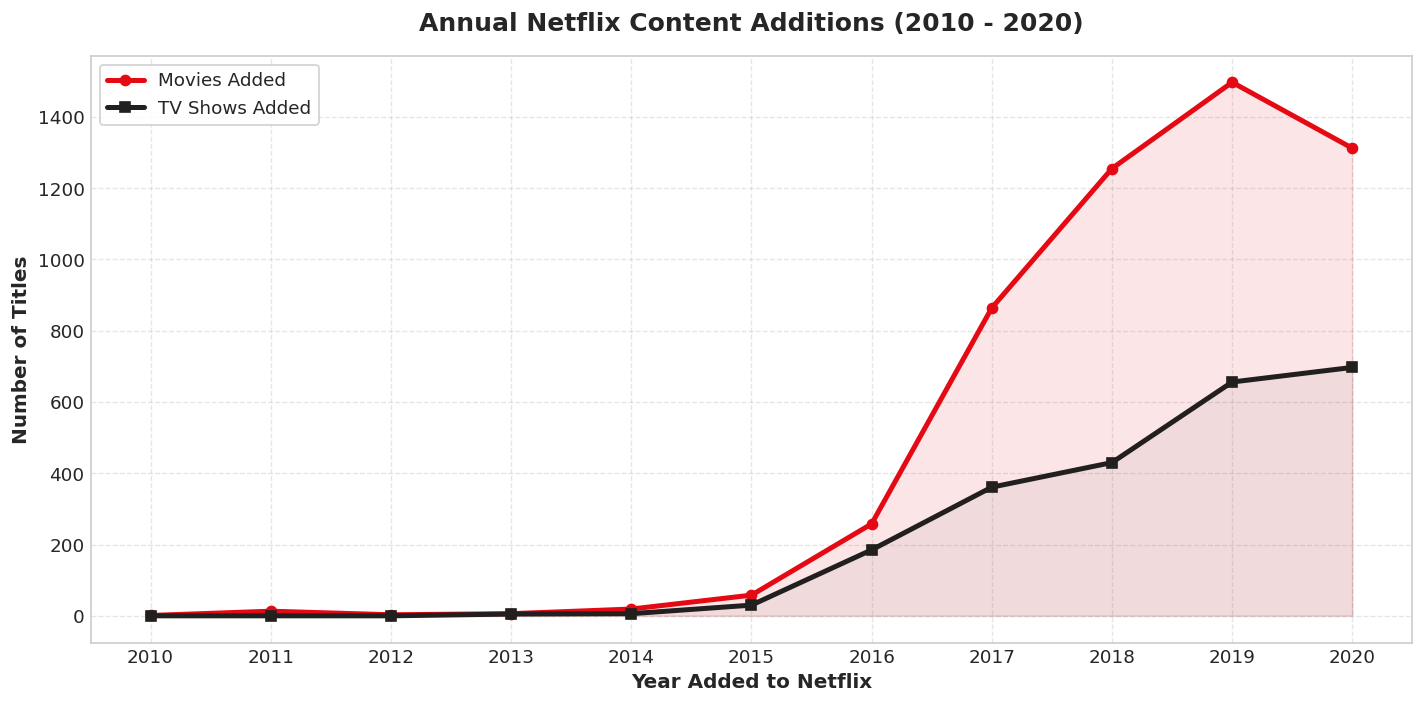

In [4]:

timeline_df = df[(df['year_added'] >= 2010) & (df['year_added'] <= 2020)]
growth_df = timeline_df.groupby(['year_added', 'type']).size().unstack(fill_value=0)

plt.figure(figsize=(12, 6))

plt.plot(growth_df.index, growth_df['Movie'], marker='o', linewidth=3, color='#E50914', label='Movies Added')
plt.plot(growth_df.index, growth_df['TV Show'], marker='s', linewidth=3, color='#221F1F', label='TV Shows Added')

# Fill area under curves for visual aesthetic
plt.fill_between(growth_df.index, growth_df['Movie'], color='#E50914', alpha=0.1)
plt.fill_between(growth_df.index, growth_df['TV Show'], color='#221F1F', alpha=0.05)

plt.title('Annual Netflix Content Additions (2010 - 2020)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Year Added to Netflix', fontsize=12, fontweight='bold')
plt.ylabel('Number of Titles', fontsize=12, fontweight='bold')
plt.xticks(growth_df.index, rotation=0)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

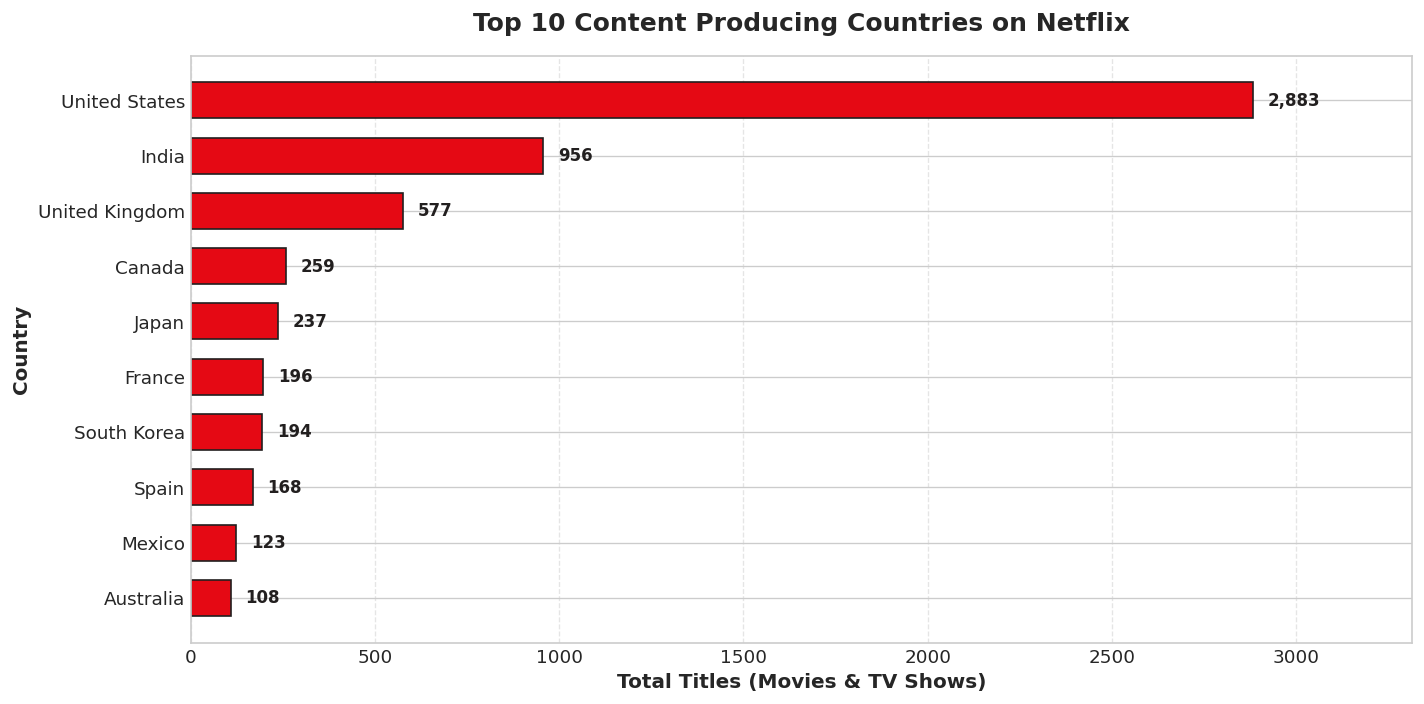

--- Top 5 Countries Breakdown ---
• United States: 2,883 titles (37.0%)
• India: 956 titles (12.3%)
• United Kingdom: 577 titles (7.4%)
• Canada: 259 titles (3.3%)
• Japan: 237 titles (3.0%)


In [5]:


top_countries = df['primary_country'].value_counts().head(10)

plt.figure(figsize=(12, 6))

# Horizontal bar plot with custom color styling
bars = plt.barh(
    top_countries.index[::-1],
    top_countries.values[::-1],
    color='#E50914',
    edgecolor='#221F1F',
    height=0.65
)

# Add exact numeric value labels at the end of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 40,
        bar.get_y() + bar.get_height() / 2,
        f'{int(width):,}',
        va='center',
        ha='left',
        fontsize=10,
        fontweight='bold',
        color='#221F1F'
    )

plt.title('Top 10 Content Producing Countries on Netflix', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Total Titles (Movies & TV Shows)', fontsize=12, fontweight='bold')
plt.ylabel('Country', fontsize=12, fontweight='bold')
plt.xlim(0, top_countries.values[0] * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

print("--- Top 5 Countries Breakdown ---")
for country, count in top_countries.head(5).items():
    print(f"• {country}: {count:,} titles ({count/len(df)*100:.1f}%)")

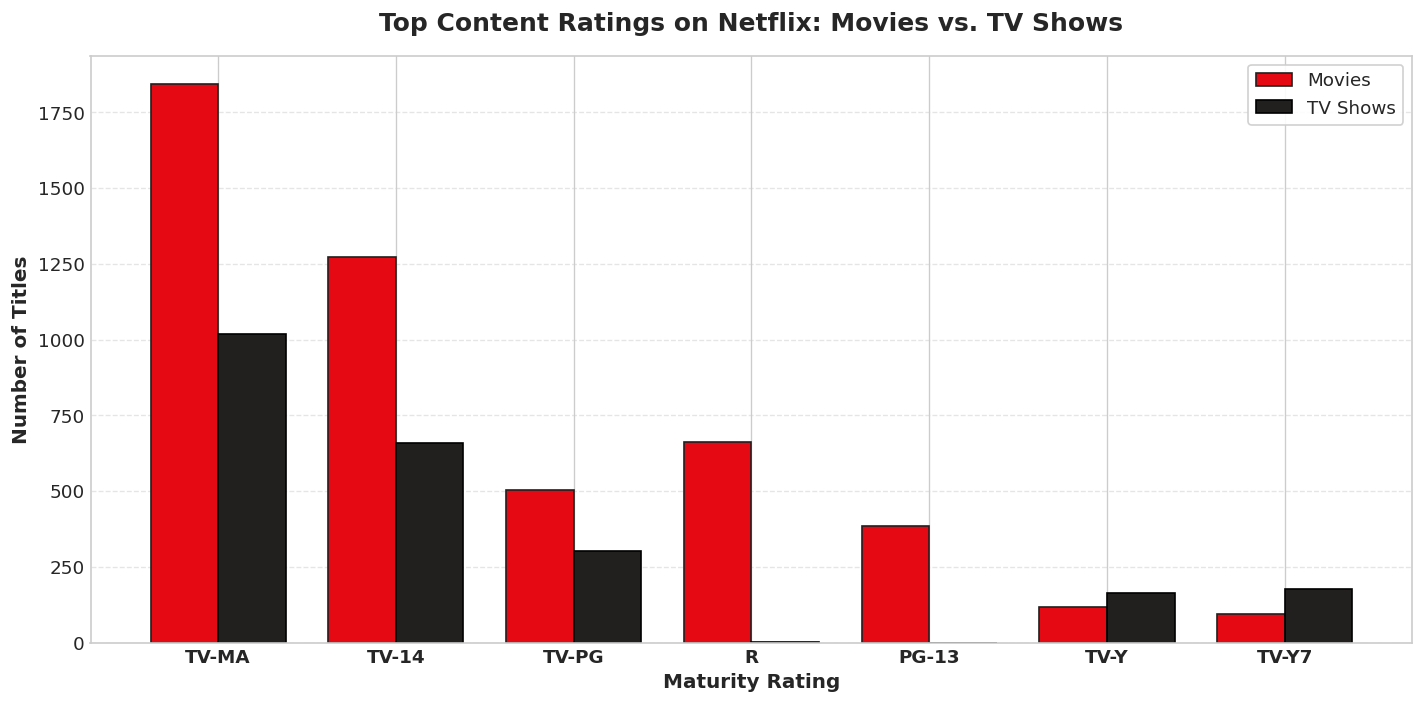

In [6]:


top_ratings = df['rating'].value_counts().head(7).index
rating_df = df[df['rating'].isin(top_ratings)]
rating_counts = rating_df.groupby(['rating', 'type']).size().unstack(fill_value=0)
rating_counts = rating_counts.loc[top_ratings]

plt.figure(figsize=(12, 6))

x = np.arange(len(top_ratings))
width = 0.38

# Grouped bars
plt.bar(x - width/2, rating_counts['Movie'], width, label='Movies', color='#E50914', edgecolor='#221F1F')
plt.bar(x + width/2, rating_counts['TV Show'], width, label='TV Shows', color='#221F1F', edgecolor='black')

plt.title('Top Content Ratings on Netflix: Movies vs. TV Shows', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Maturity Rating', fontsize=12, fontweight='bold')
plt.ylabel('Number of Titles', fontsize=12, fontweight='bold')
plt.xticks(x, top_ratings, fontsize=11, fontweight='bold')
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

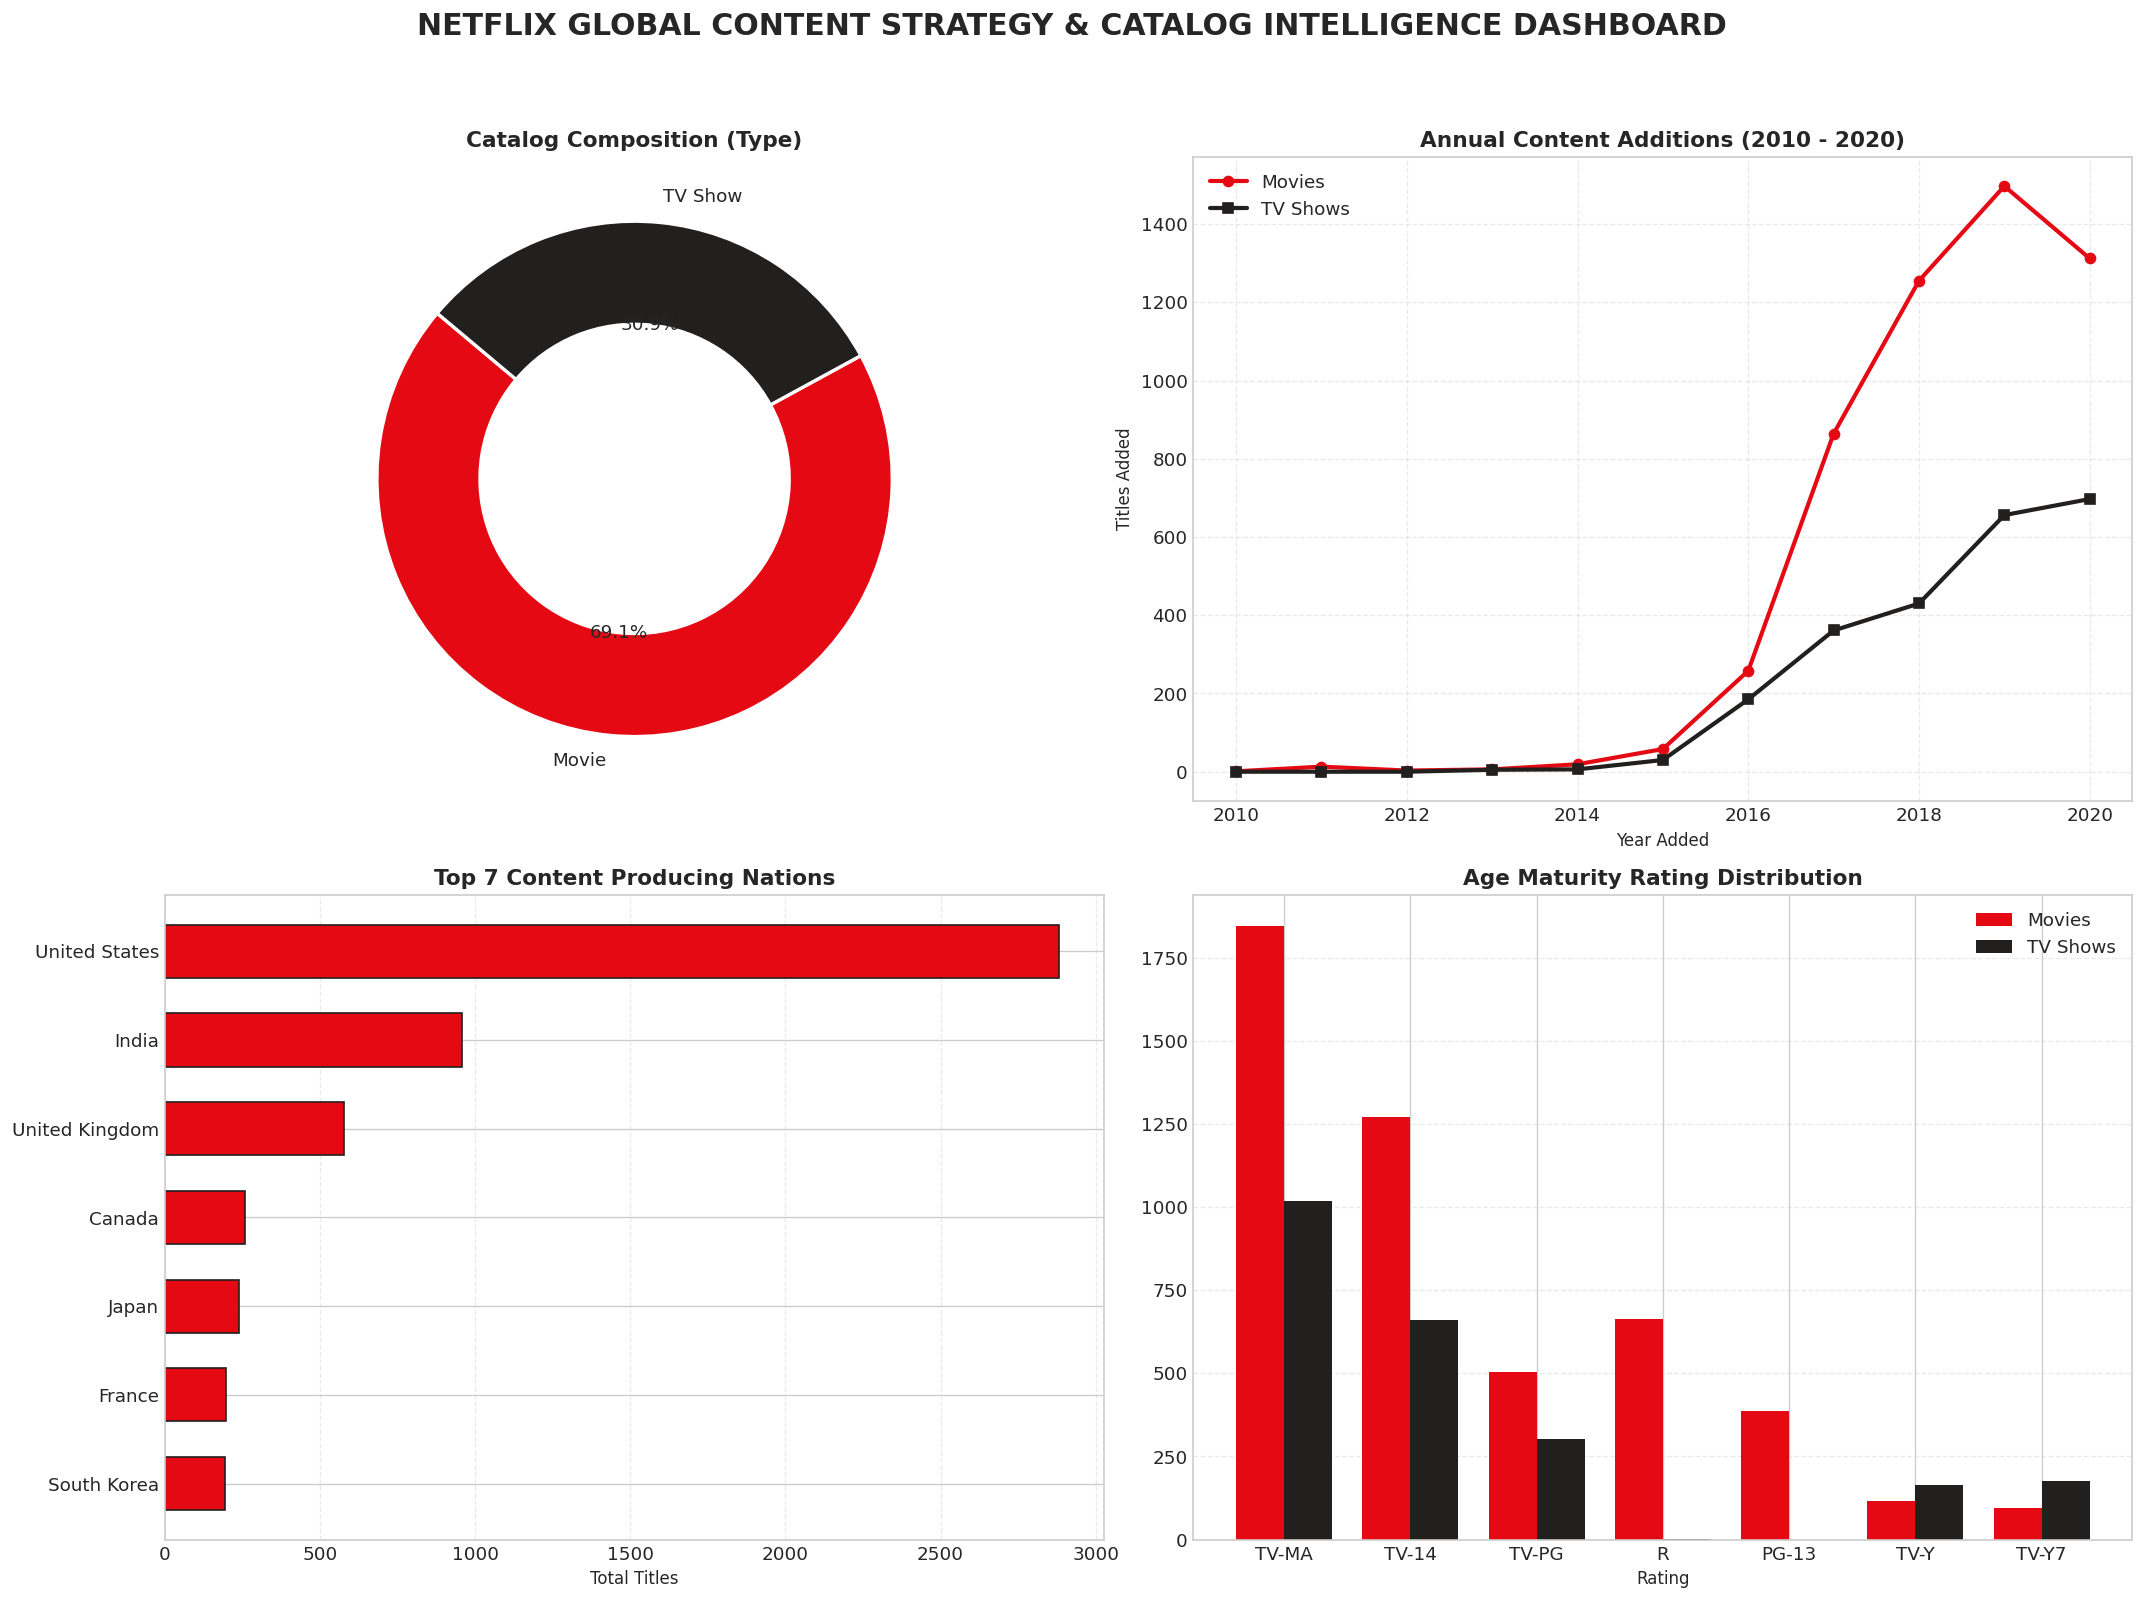

✓ Executive 4-in-1 Dashboard generated successfully!


In [7]:

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('NETFLIX GLOBAL CONTENT STRATEGY & CATALOG INTELLIGENCE DASHBOARD', fontsize=18, fontweight='bold', y=0.98)


axes[0, 0].pie(
    type_counts,
    labels=type_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#E50914', '#221F1F'],
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)
axes[0, 0].set_title('Catalog Composition (Type)', fontsize=13, fontweight='bold')


axes[0, 1].plot(growth_df.index, growth_df['Movie'], marker='o', linewidth=2.5, color='#E50914', label='Movies')
axes[0, 1].plot(growth_df.index, growth_df['TV Show'], marker='s', linewidth=2.5, color='#221F1F', label='TV Shows')
axes[0, 1].set_title('Annual Content Additions (2010 - 2020)', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Year Added', fontsize=10)
axes[0, 1].set_ylabel('Titles Added', fontsize=10)
axes[0, 1].legend()
axes[0, 1].grid(True, linestyle='--', alpha=0.4)


top_7_c = top_countries.head(7)
axes[1, 0].barh(top_7_c.index[::-1], top_7_c.values[::-1], color='#E50914', edgecolor='#221F1F', height=0.6)
axes[1, 0].set_title('Top 7 Content Producing Nations', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Total Titles', fontsize=10)
axes[1, 0].grid(axis='x', linestyle='--', alpha=0.4)


axes[1, 1].bar(x - width/2, rating_counts['Movie'], width, label='Movies', color='#E50914')
axes[1, 1].bar(x + width/2, rating_counts['TV Show'], width, label='TV Shows', color='#221F1F')
axes[1, 1].set_title('Age Maturity Rating Distribution', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Rating', fontsize=10)
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(top_ratings)
axes[1, 1].legend()
axes[1, 1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()
print("✓ Executive 4-in-1 Dashboard generated successfully!")

In [8]:


summary_data = {
    "Task 3 Requirement": [
        "1. Transform Raw Data to Visuals",
        "2. Donut Chart (Catalog Breakdown)",
        "3. Time-Series Growth Trend",
        "4. Categorical Ranking (Countries)",
        "5. Grouped Comparison (Maturity Ratings)",
        "6. Executive 4-in-1 Dashboard"
    ],
    "Visual Solution": [
        "Ingested 7,787 Netflix titles & parsed datetime features",
        "Wedge donut plot showing 69.1% Movies vs 30.9% TV Shows",
        "Dual-line area plot tracking exponential rise (2010-2020)",
        "Horizontal annotated bar chart (USA: 2,883, India: 956)",
        "Grouped bar chart highlighting TV-MA adult audience dominance",
        "Unified 2x2 multi-panel business intelligence dashboard"
    ],
    "Status": [
        "✓ Completed",
        "✓ Completed",
        "✓ Completed",
        "✓ Completed",
        "✓ Completed",
        "✓ Completed"
    ]
}

summary_df = pd.DataFrame(summary_data)

print("=" * 75)
print("CODEALPHA DATA ANALYTICS INTERNSHIP — TASK 3 FINAL REPORT")
print("=" * 75)
display(summary_df)
print("\n✓ Task 3: Data Visualization successfully completed!")

CODEALPHA DATA ANALYTICS INTERNSHIP — TASK 3 FINAL REPORT


,Task 3 Requirement,Visual Solution,Status
0,1. Transform Raw Data to Visuals,"Ingested 7,787 Netflix titles & parsed datetim...",✓ Completed
1,2. Donut Chart (Catalog Breakdown),Wedge donut plot showing 69.1% Movies vs 30.9%...,✓ Completed
2,3. Time-Series Growth Trend,Dual-line area plot tracking exponential rise ...,✓ Completed
3,4. Categorical Ranking (Countries),"Horizontal annotated bar chart (USA: 2,883, In...",✓ Completed
4,5. Grouped Comparison (Maturity Ratings),Grouped bar chart highlighting TV-MA adult aud...,✓ Completed
5,6. Executive 4-in-1 Dashboard,Unified 2x2 multi-panel business intelligence ...,✓ Completed



✓ Task 3: Data Visualization successfully completed!
